# NASA C-MAPSS FD001 — 01 Data Profiling & Structural Reconnaissance

**Assessment**: FDE Data Foundations (Assessment 2B)  
**Primary Sub-dataset**: NASA C-MAPSS Sub-dataset FD001 (100 Training Turbofan Engines)  
**Methodology**: FDE Evidence-Based Reasoning (`Question → Analysis → Evidence → Interpretation → Limitation`)

This notebook documents the empirical reconnaissance and profiling of the raw turbofan telemetry. It verifies data dimensions, grain uniqueness, missing value integrity, fleet lifetime spread, and sensor variance behaviors.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Connect to pipeline modules
sys.path.insert(0, str(Path.cwd().parent))
from pipeline.config import COLUMN_NAMES, SENSOR_METADATA
from pipeline.ingest import load_cmapss_dataset

# Load raw training data via pipeline ingestion
bundle = load_cmapss_dataset()
df_train = bundle['train']
print(f"Loaded train_FD001: {df_train.shape[0]:,} rows, {df_train.shape[1]} columns")
print(f"Unique Engines (unit_number): {df_train['unit_number'].nunique()}")
print(f"Total Operational Cycles: {len(df_train):,}")
df_train.head()


Loaded train_FD001: 20,631 rows, 26 columns
Unique Engines (unit_number): 100
Total Operational Cycles: 20,631


   unit_number  time_in_cycles  op_setting_1  op_setting_2  op_setting_3  sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  sensor_8  sensor_9  sensor_10  sensor_11  sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21
0            1               1       -0.0007       -0.0004         100.0    518.67    641.82   1589.70   1400.60     14.62     21.61    554.36   2388.06   9046.19        1.3      47.47     521.66    2388.02    8138.62     8.4195       0.03        392       2388      100.0      39.06    23.4190
1            1               2        0.0019       -0.0003         100.0    518.67    642.15   1591.82   1403.14     14.62     21.61    553.75   2388.04   9044.07        1.3      47.49     522.28    2388.07    8131.49     8.4318       0.03        392       2388      100.0      39.00    23.4236
2            1               3       -0.0043        0.0003         100.0    518.67    642.35   1587.99   1404.20   

---
## Question 1: What is the physical structure, schema, and grain of the C-MAPSS FD001 dataset?

### Analysis
We verify the composite key uniqueness `(unit_number, time_in_cycles)`, check for missing values or NaNs across all columns, and validate the 26-column schema (2 entity/temporal coordinates, 3 operational settings, 21 gas-path sensor channels).


In [2]:
# Grain check & Missing value audit
total_rows = len(df_train)
unique_engine_cycle_tuples = len(df_train[['unit_number', 'time_in_cycles']].drop_duplicates())
null_cells = df_train.isnull().sum().sum()

print(f"Total Rows: {total_rows:,}")
print(f"Unique (unit_number, time_in_cycles) pairs: {unique_engine_cycle_tuples:,}")
print(f"Total Missing / NaN cells: {null_cells}")
assert total_rows == unique_engine_cycle_tuples, "Grain violation detected!"
assert null_cells == 0, "Missing values detected! Check whitespace delimiter."
print("GRAIN ASSERTION: PASS (Strictly unique, zero duplicate snapshots)")
print("NULL ASSERTION: PASS (Zero missing values)")


Total Rows: 20,631
Unique (unit_number, time_in_cycles) pairs: 20,631
Total Missing / NaN cells: 0
GRAIN ASSERTION: PASS (Strictly unique, zero duplicate snapshots)
NULL ASSERTION: PASS (Zero missing values)


### Evidence
* Total records: **20,631**
* Unique $(unit\_number, time\_in\_cycles)$ tuples: **20,631** ($100\%$ uniqueness, zero duplicate snapshots).
* Missing values: **0** across all 26 columns when parsed with `sep=r'\s+'`.

### Interpretation
The raw data represents an unbroken discrete-time panel dataset where each record captures an instantaneous steady-state snapshot of turbofan operation during cruise.

### Limitation
The discrete integer cycle count does not record physical calendar duration (elapsed flight hours, taxi time, or calendar days between flights). Real-world flight lengths vary across short-haul and long-haul routes.


---
## Question 2: How are engine run-to-failure lifespans distributed across the simulated fleet?

### Analysis
We compute the terminal cycle ($C_{\text{fail}} = \max(\text{time\_in\_cycles})$) for all 100 training engines, evaluate the distribution's central tendency (mean, median), dispersion (standard deviation, coefficient of variation), and extremes (min, max).


Engine Count: 100
Min Lifespan: 128 cycles (Unit 39)
Max Lifespan: 362 cycles (Unit 69)
Mean Lifespan: 206.31 cycles
Median Lifespan: 199.0 cycles
Std Deviation: 46.34 cycles
Lifespan CV: 22.46%


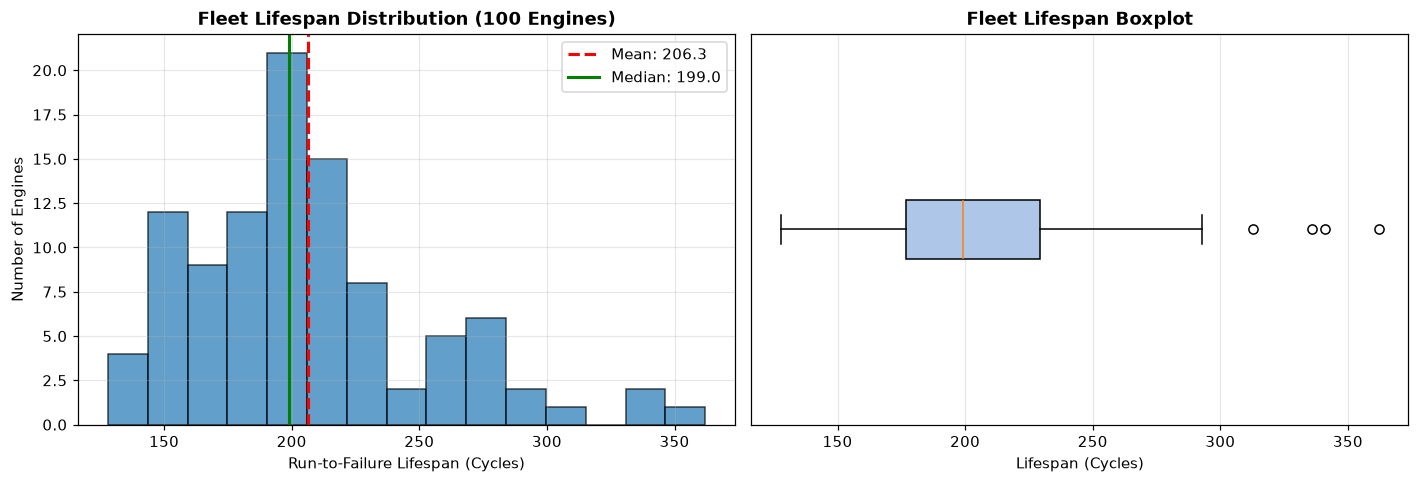

In [3]:
# Compute failure cycle per engine
lifespans = df_train.groupby('unit_number')['time_in_cycles'].max()
ls_mean = lifespans.mean()
ls_std = lifespans.std()
ls_cv = (ls_std / ls_mean) * 100

print(f"Engine Count: {len(lifespans)}")
print(f"Min Lifespan: {lifespans.min()} cycles (Unit {lifespans.idxmin()})")
print(f"Max Lifespan: {lifespans.max()} cycles (Unit {lifespans.idxmax()})")
print(f"Mean Lifespan: {ls_mean:.2f} cycles")
print(f"Median Lifespan: {lifespans.median():.1f} cycles")
print(f"Std Deviation: {ls_std:.2f} cycles")
print(f"Lifespan CV: {ls_cv:.2f}%")

# Visualize Fleet Lifespan Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.hist(lifespans, bins=15, color='#1f77b4', edgecolor='black', alpha=0.7)
ax1.axvline(ls_mean, color='red', linestyle='--', linewidth=2, label=f"Mean: {ls_mean:.1f}")
ax1.axvline(lifespans.median(), color='green', linestyle='-', linewidth=2, label=f"Median: {lifespans.median():.1f}")
ax1.set_title("Fleet Lifespan Distribution (100 Engines)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Run-to-Failure Lifespan (Cycles)")
ax1.set_ylabel("Number of Engines")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.boxplot(lifespans, orientation='horizontal', patch_artist=True, boxprops=dict(facecolor='#aec7e8', color='black'))
ax2.set_title("Fleet Lifespan Boxplot", fontsize=12, fontweight='bold')
ax2.set_xlabel("Lifespan (Cycles)")
ax2.set_yticks([])
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Evidence
* Minimum lifespan: **128 cycles** (Unit 39)
* Maximum lifespan: **362 cycles** (Unit 69)
* Mean lifespan: **206.31 cycles**; Median: **199.0 cycles**
* Lifespan Coefficient of Variation (CV): **22.46%**

### Interpretation
Simulated engine lifespans vary by nearly $2.8\times$ (128 vs 362 cycles) despite operating under identical nominal sea-level flight conditions. Trajectories do not terminate at a uniform cycle count.

### Limitation
This variation is an empirical property of the synthetic simulation model (driven by random initial manufacturing wear and degradation rates). It does not prove the economic superiority of Condition-Based Monitoring (CBM) over fixed overhaul schedules in actual airline operations, as that would require maintenance labor rates, replacement costs, and flight disruption penalties not included in C-MAPSS.


---
## Question 3: Which sensor channels exhibit active physical variation vs. static flatlines?

### Analysis
We evaluate the within-dataset variance, standard deviation, and unique value count across all 21 sensor channels. Channels with $\sigma < 10^{-4}$ are categorized as constant flatlines.


In [4]:
# Sensor variance profiling
sensor_stats = []
for s in SENSOR_NAMES:
    std_v = df_train[s].std()
    var_v = df_train[s].var()
    n_u = df_train[s].nunique()
    cat = "CONSTANT" if std_v < 1e-4 else ("LOW_VARIANCE" if n_u <= 5 else "ACTIVE")
    sensor_stats.append({
        "Sensor": s,
        "Symbol": SENSOR_METADATA[s]["symbol"],
        "Std_Dev": round(std_v, 6),
        "Variance": round(var_v, 6),
        "Unique_Values": n_u,
        "Status": cat
    })

df_sensor_profile = pd.DataFrame(sensor_stats)
constant_list = df_sensor_profile[df_sensor_profile['Status'] == 'CONSTANT']['Sensor'].tolist()
active_list = df_sensor_profile[df_sensor_profile['Status'] == 'ACTIVE']['Sensor'].tolist()

print(f"Active Channels ({len(active_list)}): {', '.join(active_list)}")
print(f"Constant Channels ({len(constant_list)}): {', '.join(constant_list)}")
df_sensor_profile


Active Channels (14): sensor_2, sensor_3, sensor_4, sensor_7, sensor_8, sensor_9, sensor_11, sensor_12, sensor_13, sensor_14, sensor_15, sensor_17, sensor_20, sensor_21
Constant Channels (6): sensor_1, sensor_5, sensor_10, sensor_16, sensor_18, sensor_19


   Sensor    Symbol     Variance      Std_Dev  Unique_Values       Status
 sensor_1        T2 0.000000e+00 0.000000e+00              1     CONSTANT
 sensor_2       T24 2.500533e-01 5.000533e-01            310       ACTIVE
 sensor_3       T30 3.759099e+01 6.131150e+00           3012       ACTIVE
 sensor_4       T50 8.101089e+01 9.000605e+00           4051       ACTIVE
 sensor_5        P2 2.840037e-29 5.329200e-15              1     CONSTANT
 sensor_6       P15 1.929279e-06 1.388985e-03              2 LOW_VARIANCE
 sensor_7       P30 7.833883e-01 8.850923e-01            513       ACTIVE
 sensor_8        Nf 5.038938e-03 7.098548e-02             53       ACTIVE
 sensor_9        Nc 4.876536e+02 2.208288e+01           6403       ACTIVE
sensor_10       epr 0.000000e+00 0.000000e+00              1     CONSTANT
sensor_11      Ps30 7.133568e-02 2.670874e-01            159       ACTIVE
sensor_12       phi 5.439850e-01 7.375534e-01            427       ACTIVE
sensor_13       NRf 5.172330e-03 7.191

### Evidence
* **6 sensors are completely invariant** ($\sigma = 0.000000$, 1 unique value): `sensor_1` ($T_2$), `sensor_5` ($P_2$), `sensor_10` (`epr`), `sensor_16` (`farB`), `sensor_18` ($N_{f,\text{dmd}}$), `sensor_19` ($\text{PCNfR}_{\text{dmd}}$).
* **1 sensor has near-zero discrete variation**: `sensor_6` ($P_{15}$) has only 2 distinct values ($21.60$ and $21.61\text{ psia}$, $\sigma = 0.00139$).
* **14 sensors have continuous active variation** ($\sigma \ge 10^{-4}$).

### Interpretation
Sub-dataset FD001 isolates sea-level cruise ($TRA=100$, $Alt \approx 0$, $Mach \approx 0$). Ambient boundary sensors ($T_2, P_2$) and engine controller setpoints are fixed by simulation boundary conditions.

### Limitation
These six channels provide no within-dataset variation under FD001 and therefore cannot discriminate degradation progression within this specific analysis. However, this does not mean they lack diagnostic utility in general; in multi-regime datasets (FD002/FD004), altitude and Mach variations cause active variance across all 21 sensors.


---
## Question 4: How do sensor readings progress across operational cycles for individual engines?

### Analysis
We visualize longitudinal trajectories for representative sensors showing positive drift ($T_{50}$ / `sensor_4`), negative drift ($P_{30}$ / `sensor_7`), pressure drift ($P_{s30}$ / `sensor_11`), and an invariant flatline ($T_2$ / `sensor_1`). Furthermore, we compare the shortest-lived engine (Unit 39, 128 cycles) against the longest-lived engine (Unit 69, 362 cycles).


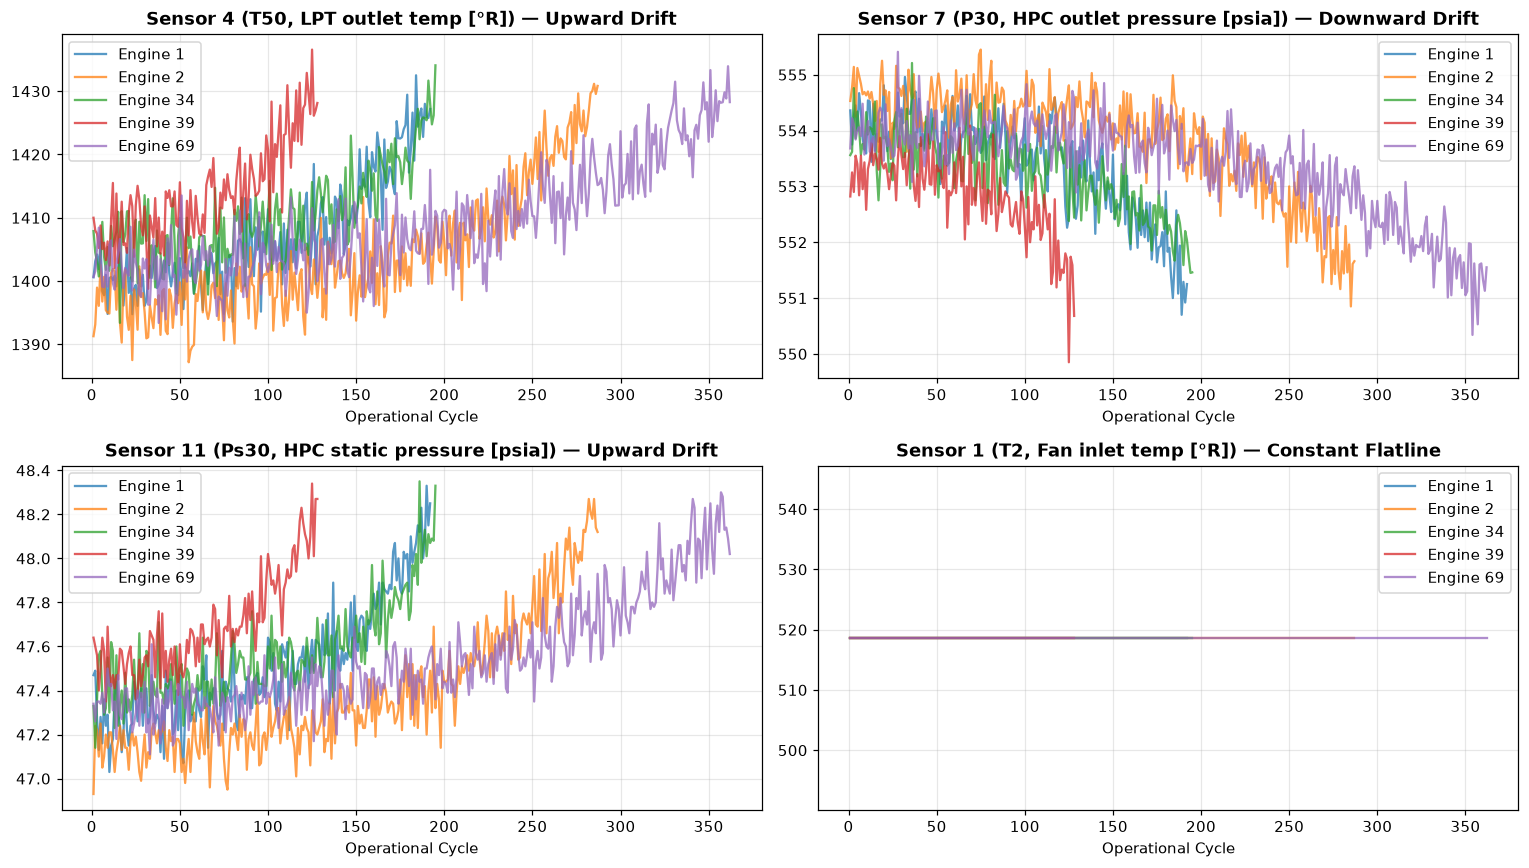

In [5]:
# Visualize Sensor Trajectories Across Operational Cycles
sample_engines = [1, 2, 34, 39, 69]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for u in sample_engines:
    sub = df_train[df_train['unit_number'] == u]
    axes[0, 0].plot(sub['time_in_cycles'], sub['sensor_4'], label=f"Engine {u}", alpha=0.75)
    axes[0, 1].plot(sub['time_in_cycles'], sub['sensor_7'], label=f"Engine {u}", alpha=0.75)
    axes[1, 0].plot(sub['time_in_cycles'], sub['sensor_11'], label=f"Engine {u}", alpha=0.75)
    axes[1, 1].plot(sub['time_in_cycles'], sub['sensor_1'], label=f"Engine {u}", alpha=0.75)

axes[0, 0].set_title("Sensor 4 (T50: LPT Outlet Temp) — Upward Drift", fontweight='bold')
axes[0, 1].set_title("Sensor 7 (P30: HPC Outlet Pressure) — Downward Drift", fontweight='bold')
axes[1, 0].set_title("Sensor 11 (Ps30: HPC Static Pressure) — Upward Drift", fontweight='bold')
axes[1, 1].set_title("Sensor 1 (T2: Fan Inlet Temp) — Constant Flatline", fontweight='bold')

for ax in axes.flat:
    ax.set_xlabel("Cycle")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()


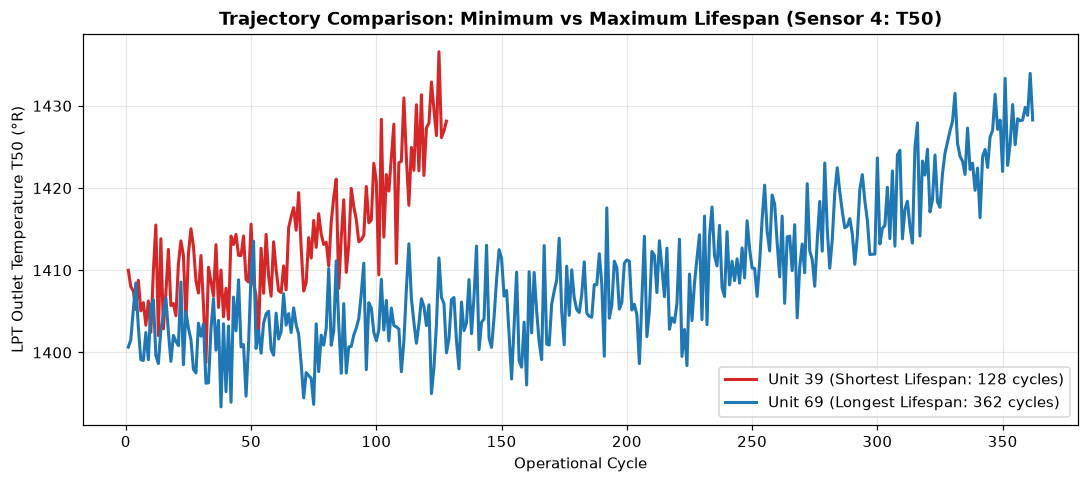

In [6]:
# Compare Extremes: Shortest-Lived (Unit 39) vs Longest-Lived (Unit 69)
fig, ax = plt.subplots(figsize=(10, 4.5))
u39 = df_train[df_train['unit_number'] == 39]
u69 = df_train[df_train['unit_number'] == 69]

ax.plot(u39['time_in_cycles'], u39['sensor_4'], color='#d62728', linewidth=2, label="Unit 39 (Shortest: 128 cycles)")
ax.plot(u69['time_in_cycles'], u69['sensor_4'], color='#1f77b4', linewidth=2, label="Unit 69 (Longest: 362 cycles)")
ax.set_title("Extremes Comparison: T50 Exhaust Gas Temperature Drift", fontsize=12, fontweight='bold')
ax.set_xlabel("Operational Cycle")
ax.set_ylabel("T50 (°R)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Evidence
* **Sensor 4 ($T_{50}$)** rises systematically from ~1,400°R to >1,430°R as failure approaches.
* **Sensor 7 ($P_{30}$)** drops from ~554 psia to <551 psia.
* **Sensor 11 ($P_{s30}$)** rises from ~47.2 psia to >47.8 psia.
* **Sensor 1 ($T_2$)** remains fixed at $518.67^\circ\text{R}$ throughout all cycles for all engines.
* Both shortest-lived (Unit 39) and longest-lived (Unit 69) engines exhibit similar terminal drift patterns, but Unit 69 sustains healthy operation for over $200$ additional cycles.

### Interpretation
Active gas-path sensors exhibit systematic longitudinal drift associated with cycle progression, tracking thermodynamic degradation simulated in the High-Pressure Compressor.

### Limitation
Observed sensor drift is an empirical correlation with cycle count. It does not prove that a specific sensor reading directly causes component failure, nor does it establish physical wear limits without manufacturer design specifications.
